# Notebook 6: Block cellular Automata and their Spectral analysis
The aim of the first part of the notebook is not to keep building upon the fucntions defined earlier, but pause for a second and use the functions defined in the past to simulate 1-d wave interference.

The aim of the second part is to define block Cellular Automata and explain why they are so useful for simulating problems in physics.

In [1]:
import numpy as np

from itertools import permutations, product

In [2]:
from Functions_for_Notebook_1 import make_rule, make_rule_zero_condition, make_rule_symmetry #For making the rules

from Functions_for_Notebook_1 import dynamics, dynamics_reflection, dynamics_periodic #For the dynamics

from Functions_for_Notebook_1 import plot_grid #For the plotting

## 4.1) Exploring causality bounds in elementary CA grids
In special relativity, the light cone of an event is the set of spacetime points reachable by signals at speed $c$, the surface $c^2\Delta t^2 = \Delta x^2+\Delta y^2+\Delta z^2$. It divides spacetime into three regions relative to the event:

Future cone: events it can influence.
Past cone: events that can influence it.
Elsewhere: spacelike-separated events, causally disconnected from it in both directions.

Because the interval $c^2\Delta t^2-\Delta\mathbf{x}^2$ is invariant under Lorentz transformations, all inertial observers agree on the cone. They agree on which events are causally ordered even when they disagree about simultaneity for spacelike pairs.

This same concept can be encounteres in the 2-d lattice showing the evolution of a classical CA through its discrete timesteps. The CA cone plays the same causal role, with $c=1$ cell/step, because only a neighboring cell can affect anotehr cell. The difference is that it’s fixed by the lattice: there are no boosts that preserve it, so it is a causal structure without Lorentz symmetry.

https://arxiv.org/html/2602.20623v1

These limits in the propagation of information inside the system will also include damage and entropy of the system. So each given system will have a maximum lyapunov exponent and Shannon entropy capped by this causal effect.

For cell i, cell i at t+1 is a fucntion of cell i-r and cell i+r. In the case of elementary CA, r = 1.

### 4.1.1) Lyapunov exponent capped by causality
For t timesteps, cell i will be a fucntion of cell i-rt and cell i+rt, so cell i-t and i+t.

### 4.1.2) Shannon entropy capped by causality

## 4.2) Recreating classical particle collision with rule 54

Rule 54 is a specially relevant rule for physics, it is a class IV rule that produces the following shapes:
- 

## 4.3) (Classical) Block Cellular Automata
### 4.3.1) How their evolution works
Block cellular Automata are a special type of CA that fixes the irreversibility issue of ordinary CA by construction.

In ordinary CA, each cell of the grid is updated individually given a the rule. In block CA, the lattice is divided into non-overlapping regions and the rule is applied to each region. In order to apply a rule to a region, you choose form a permutation and because permutattions are invertible, then the system is always invertible. An example, for blocks consising of two cells, would be the following:

{00,01,10,11}→{11,10,01,00}

### 4.3.2) Different types of evolution
Any evolution can be defined and its reversibility will depend on its construction, though all permutations will be reversible. There are examples of evolutions that are used frequently:
- identity: (a,b)→(a,b) 
- SWAP: (a,b)→(b,a) 
- XOR-into-first: (a,b)→(a⊕b, b)
- NOT-both: (a,b)→(¬a,¬b)

### 4.3.3) Different partition schemes
In one dimension, the partition schemes comes down only to how many cells you include in each block. For now, only one dimensional block CA are looked at.

### 4.3.4) Coding the dynamics

In [3]:
def block_dynamics(initial_conditions, L, block_map, n_steps, block_size=2):
    assert L % block_size == 0, "L must be divisible by block_size"

    state = np.zeros(L, dtype=int)
    state[np.asarray(initial_conditions, dtype=int)] = 1

    grid = np.empty((n_steps + 1, L), dtype=int)
    grid[0] = state

    for t in range(n_steps):
        offset = t % block_size
        new_state = state.copy()
        for i in range(offset, L, block_size):
            idx = [(i + k) % L for k in range(block_size)]
            block_in = tuple(state[idx])
            block_out = block_map(block_in)
            for pos, val in zip(idx, block_out):
                new_state[pos] = val
        state = new_state
        grid[t + 1] = state

    return grid[::-1] # because the output is a numpy grid, then plotting will work with the functions defined earlier

Now, we will define the block_map possibilities:

In [4]:
def identity_n(block):
    return block

def swap2(block):
    a, b = block
    return (b, a)

def xor_into_first(block):
    a, b = block
    return (a ^ b, b)

def not_both(block):
    a, b = block
    return (1 - a, 1 - b)

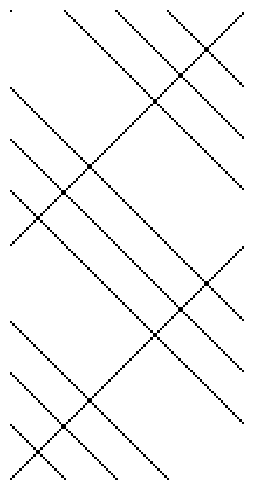

In [5]:
system = block_dynamics([0,45,67,23], 100, swap2, 200)

plot_grid(system)

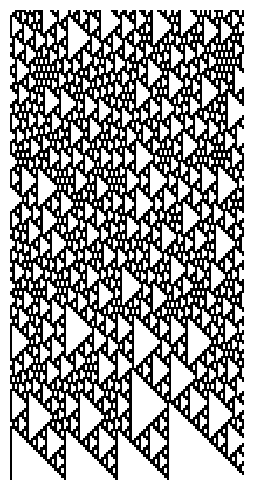

In [6]:
system = block_dynamics([0,45,67,23], 100, xor_into_first, 200)

plot_grid(system)

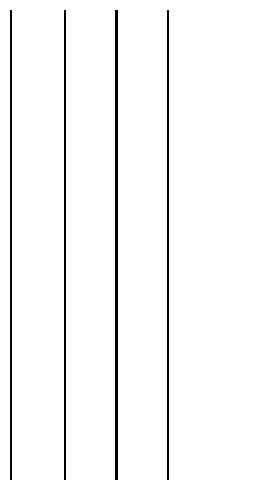

In [7]:
system = block_dynamics([0,45,67,23], 100, identity_n, 200)

plot_grid(system)

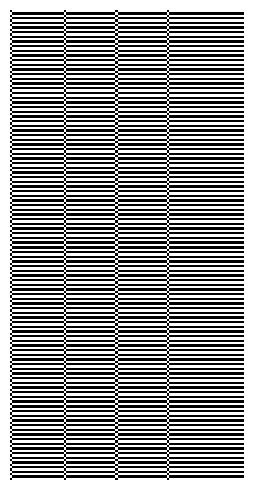

In [8]:
system = block_dynamics([0,45,67,23], 100, not_both, 200)

plot_grid(system)

### 4.2.5) Modeling the dynamics of classical block Cellular Automata with matrices 

The dynamics will now be computed in terms of matrix vector multiplication. Like in elementary CA, this method is too computationally expensive for bigger lattices, but a spectral analysis of the matrix describing the evolution of the system can shed useful information on the system.

The first function that will be defined is _bits. Bits defines all the possible configuration in lattice of length L.

In [13]:
import numpy as np
import scipy.sparse as sp

def _bits(L):
    """(2^L, L) bit table; cell 0 = MSB."""
    return (np.arange(2**L)[:, None] >> np.arange(L - 1, -1, -1)) & 1

for i in range(3, 10):
    print(_bits(i))

[[0 0 0]
 [0 0 1]
 [0 1 0]
 [0 1 1]
 [1 0 0]
 [1 0 1]
 [1 1 0]
 [1 1 1]]
[[0 0 0 0]
 [0 0 0 1]
 [0 0 1 0]
 [0 0 1 1]
 [0 1 0 0]
 [0 1 0 1]
 [0 1 1 0]
 [0 1 1 1]
 [1 0 0 0]
 [1 0 0 1]
 [1 0 1 0]
 [1 0 1 1]
 [1 1 0 0]
 [1 1 0 1]
 [1 1 1 0]
 [1 1 1 1]]
[[0 0 0 0 0]
 [0 0 0 0 1]
 [0 0 0 1 0]
 [0 0 0 1 1]
 [0 0 1 0 0]
 [0 0 1 0 1]
 [0 0 1 1 0]
 [0 0 1 1 1]
 [0 1 0 0 0]
 [0 1 0 0 1]
 [0 1 0 1 0]
 [0 1 0 1 1]
 [0 1 1 0 0]
 [0 1 1 0 1]
 [0 1 1 1 0]
 [0 1 1 1 1]
 [1 0 0 0 0]
 [1 0 0 0 1]
 [1 0 0 1 0]
 [1 0 0 1 1]
 [1 0 1 0 0]
 [1 0 1 0 1]
 [1 0 1 1 0]
 [1 0 1 1 1]
 [1 1 0 0 0]
 [1 1 0 0 1]
 [1 1 0 1 0]
 [1 1 0 1 1]
 [1 1 1 0 0]
 [1 1 1 0 1]
 [1 1 1 1 0]
 [1 1 1 1 1]]
[[0 0 0 0 0 0]
 [0 0 0 0 0 1]
 [0 0 0 0 1 0]
 [0 0 0 0 1 1]
 [0 0 0 1 0 0]
 [0 0 0 1 0 1]
 [0 0 0 1 1 0]
 [0 0 0 1 1 1]
 [0 0 1 0 0 0]
 [0 0 1 0 0 1]
 [0 0 1 0 1 0]
 [0 0 1 0 1 1]
 [0 0 1 1 0 0]
 [0 0 1 1 0 1]
 [0 0 1 1 1 0]
 [0 0 1 1 1 1]
 [0 1 0 0 0 0]
 [0 1 0 0 0 1]
 [0 1 0 0 1 0]
 [0 1 0 0 1 1]
 [0 1 0 1 0 0]
 [0 1 0 1 0 1]
 [0

The second fucntion defined is _codes. _codes is the inverse of _bits

In [14]:
def _codes(X):
    return X @ (1 << np.arange(X.shape[-1] - 1, -1, -1))

In [ ]:
def _codes(X):
    return X @ (1 << np.arange(X.shape[-1] - 1, -1, -1))

def block_matrix(block_map, b=2):
    """Column-stochastic P[out, in] (2^b x 2^b) from a callable or an array."""
    if callable(block_map):
        out = np.array([block_map(tuple(int(x) for x in r)) for r in _bits(b)], dtype=int)
        P = np.zeros((2**b, 2**b))
        P[_codes(out), np.arange(2**b)] = 1.0
    else:
        P = np.asarray(block_map, dtype=float)
    assert P.shape == (2**b, 2**b) and np.allclose(P.sum(0), 1), "P must be column-stochastic"
    return P

def block_layer_matrix(block_map, L, offset, b=2):
    """Markov matrix of one partition layer. M[i, j] = P(j -> i)."""
    assert L % b == 0, "L must be divisible by b"
    P = sp.csr_matrix(block_matrix(block_map, b))
    K = P
    for _ in range(L // b - 1):
        K = sp.kron(K, P, format="csr")             # offset-0 layer
    r = _codes(np.roll(_bits(L), -offset, axis=1))  # state x -> roll(x, -offset)
    return K[r][:, r]                               # R^T K R, no matmul needed

def block_period_matrix(block_map, L, b=2):
    """One full offset cycle: M_{b-1} ... M_1 M_0."""
    T = block_layer_matrix(block_map, L, 0, b)
    for o in range(1, b):
        T = block_layer_matrix(block_map, L, o, b) @ T
    return T

def markov_block_dynamics(initial_conditions, L, block_map, n_steps, b=2, p0=None):
    """Evolve a distribution over 2^L configurations.
    Returns (density, probs): density[t, i] = <n_i>(t), probs[t] = distribution.
    Both are reversed (grid[0] = last step), matching dynamics()."""
    layers = [block_layer_matrix(block_map, L, o, b) for o in range(b)]
    if p0 is None:
        x = np.zeros(L, dtype=int)
        x[np.asarray(initial_conditions, dtype=int)] = 1
        p = np.zeros(2**L)
        p[_codes(x)] = 1.0
    else:
        p = np.asarray(p0, dtype=float)

    probs = np.empty((n_steps + 1, 2**L))
    probs[0] = p
    for t in range(n_steps):
        p = layers[t % b] @ p
        probs[t + 1] = p

    density = probs @ _bits(L)
    return density[::-1], probs[::-1]

### 4.2.6) Verifying it matches the original dynamics function

## 4.3) Probabilistic block Cellular Automata
### 4.3.1) Defining the dynamics
Following the definition from the previous notebook on randomized elementary Classical Automata, then a function describing a randomized version of block Cellular Automata would be the following:

In [10]:
def probabilistic_block_dynamics(initial_conditions, L, block_map, n_steps,
                             probability, block_size=2, rng=None):
    assert L % block_size == 0, "L must be divisible by block_size"
    if rng is None:
        rng = np.random.default_rng()

    state = np.zeros(L, dtype=int)
    state[np.asarray(initial_conditions, dtype=int)] = 1

    grid = np.empty((n_steps + 1, L), dtype=int)
    grid[0] = state

    for t in range(n_steps):
        offset = t % block_size
        new_state = state.copy()
        for i in range(offset, L, block_size):
            idx = [(i + k) % L for k in range(block_size)]
            block_in = tuple(state[idx])
            block_out = block_map(block_in)
            for pos, val in zip(idx, block_out):
                new_state[pos] = val

        # apply independent bit flips with probability flip_prob
        flips = rng.random(L) < probability
        new_state = np.where(flips, 1 - new_state, new_state)

        state = new_state
        grid[t + 1] = state

    return grid[::-1]

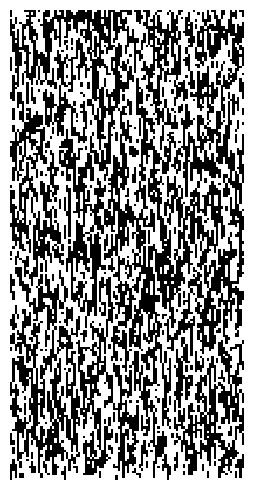

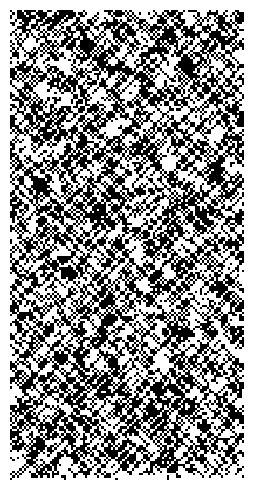

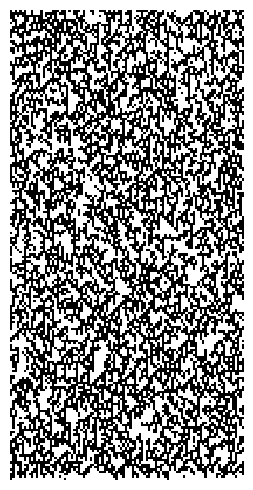

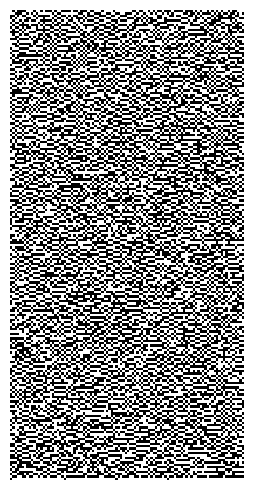

None None None None


In [11]:
system_1 = probabilistic_block_dynamics([0,45,67,23], 100, identity_n, 200, 0.2)
system_2 = probabilistic_block_dynamics([0,45,67,23], 100, swap2, 200, 0.2)
system_3 = probabilistic_block_dynamics([0,45,67,23], 100, xor_into_first, 200, 0.2)
system_4 = probabilistic_block_dynamics([0,45,67,23], 100, not_both, 200, 0.2)

print(plot_grid(system_1), plot_grid(system_2), plot_grid(system_3), plot_grid(system_4))

### 4.3.2) Dynamics of probabilistic block CA with matrices

## 4.4) Spectral analysis of matrices for block CA
### 4.4.1) Classical block CA